# Training (Simple, Complete)
Initialize multi-stage curriculum training and monitor losses.
All checkpoints are saved under clean_simulation/outputs/checkpoints.

# Training (Simple)
Train and save a checkpoint in a few lines.

Checkpoint is saved under clean_simulation/outputs/checkpoints.

In [2]:
from pathlib import Path
import sys
import h5py
import importlib
from datetime import datetime


# ── Utilities ──────────────────────────────────────────────────────────────────
def log(msg: str) -> None:
    print(f"[{datetime.now().strftime('%H:%M:%S')}] {msg}", flush=True)


def summarize_losses(name: str, summary: dict | None) -> None:
    if not summary:
        log(f"{name}: no summary available")
        return
    losses = summary.get("val_phys_losses") or summary.get("val_losses", [])
    train  = summary.get("train_phys_losses") or summary.get("train_losses", [])
    if not losses:
        log(f"{name}: no validation losses recorded")
        return
    best_idx = min(range(len(losses)), key=lambda i: losses[i])
    log(
        f"{name}: first={losses[0]:.6f}  best={losses[best_idx]:.6f} (epoch {best_idx+1})"
        f"  last={losses[-1]:.6f}  plateau_gap={losses[-1]-losses[best_idx]:+.6f}"
    )
    if train:
        log(f"{name}: generalization gap (val-train) = {losses[-1]-train[-1]:+.6f}")


def is_readable_h5(path: Path) -> bool:
    if not path.exists():
        return False
    try:
        with h5py.File(path, "r") as f:
            list(f.keys())
        return True
    except OSError:
        return False


def save_summary(name: str, summary: dict | None) -> None:
    if not summary:
        return
    try:
        import torch
        root_dir = Path.cwd().resolve()
        while root_dir != root_dir.parent and not (root_dir / "clean_simulation").is_dir():
            root_dir = root_dir.parent
        ckpt_dir = root_dir / "clean_simulation" / "outputs" / "checkpoints"
        ckpt_dir.mkdir(parents=True, exist_ok=True)
        path = ckpt_dir / f"{name}_summary.pt"
        torch.save(summary, path)
        log(f"Saved {name} summary history safely to disk: {path}")
    except Exception as e:
        log(f"Warning: Could not save summary {name} to disk: {e}")


def load_summary(name: str) -> dict | None:
    try:
        import torch
        root_dir = Path.cwd().resolve()
        while root_dir != root_dir.parent and not (root_dir / "clean_simulation").is_dir():
            root_dir = root_dir.parent
        ckpt_dir = root_dir / "clean_simulation" / "outputs" / "checkpoints"
        path = ckpt_dir / f"{name}_summary.pt"
        if path.exists():
            summary = torch.load(path, map_location="cpu")
            log(f"Loaded {name} summary history from disk successfully.")
            return summary
    except Exception as e:
        log(f"Warning: Could not load {name} summary from disk: {e}")
    return None


# ── Workspace root ─────────────────────────────────────────────────────────────
log("Locating workspace root...")
root = Path.cwd().resolve()
while root != root.parent and not (root / "clean_simulation").is_dir():
    root = root.parent
if not (root / "clean_simulation").is_dir():
    raise RuntimeError("Could not find workspace root containing clean_simulation/")
log(f"Workspace root: {root}")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))


# ── Imports (forced reload for notebook re-runs) ───────────────────────────────
log("Importing training modules...")
import clean_simulation.internal_nn_runtime.cutcell_ml.config   as cutcell_cfg_module
import clean_simulation.internal_nn_runtime.cutcell_ml.data     as cutcell_data_module
import clean_simulation.internal_nn_runtime.cutcell_ml.model    as cutcell_model_module
import clean_simulation.internal_nn_runtime.cutcell_ml.training as cutcell_training_module
import clean_simulation.internal_nn_runtime.cutcell_ml.pipeline as cutcell_pipeline_module
import clean_simulation.internal_nn_runtime.cutcell_ml          as cutcell_ml_module
import clean_simulation.internal_nn_runtime.workflows            as workflows_module

for mod in [
    cutcell_cfg_module, cutcell_data_module, cutcell_model_module,
    cutcell_training_module, cutcell_pipeline_module, cutcell_ml_module, workflows_module,
]:
    importlib.reload(mod)

DataConfig           = cutcell_cfg_module.DataConfig
RunConfig            = cutcell_cfg_module.RunConfig
TrainingConfig       = cutcell_cfg_module.TrainingConfig
train_cutcell_model  = workflows_module.train_cutcell_model
load_and_concat_h5_files = cutcell_data_module.load_and_concat_h5_files
log("Imports ready")


# ── Multi-Dataset Loading ──────────────────────────────────────────────────────
data_dir = root / "clean_simulation" / "outputs" / "data"

# Find all generated QUESO H5 files (excluding temp/profile files)
queso_files = [f for f in sorted(data_dir.glob("*queso*.h5")) if not f.name.startswith("_")]
# Remove duplicates while preserving order
seen = set()
unique_files = []
for f in queso_files:
    if f.name not in seen:
        seen.add(f.name)
        unique_files.append(f)

# If no specific files are found, use all H5 files that contain our desired group
if not unique_files:
    unique_files = sorted(data_dir.glob("*.h5"))

# Define high-level dataset specs for multi-geometry training using the QuESo-backed files
multi_geometry_specs = []
for h5_p in unique_files:
    try:
        with h5py.File(h5_p, "r") as f_h5:
            # We look for integration_2_poly_1 group
            valid_grp = None
            for g in ["integration_2_poly_1", "depth_4_integration_2_poly_1", "depth_2_integration_2_poly_1"]:
                if g in f_h5:
                    valid_grp = g
                    break
            if valid_grp is not None:
                multi_geometry_specs.append((h5_p, valid_grp, 0.3))
    except (OSError, KeyError):
        continue

log(f"Loading and combining datasets for multi-geometry training: found {len(multi_geometry_specs)} datasets...")
readable_specs = []
for h5_p, grp_n, nu in multi_geometry_specs:
    if is_readable_h5(h5_p):
        readable_specs.append((h5_p, grp_n, nu))
        log(f"  OK   {h5_p.name} / {grp_n}")
    else:
        log(f"  SKIP {h5_p.name} / {grp_n} (not found or invalid)")

# If no readable spec found, fallback to default list
if not readable_specs:
    log("Warning: Specified multi-geometry datasets not found. Falling back to default list.")
    candidates_h5 = sorted(
        data_dir.glob("local_stiffness_matrices_queso_i2_p1.h5"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    for p in candidates_h5:
        if is_readable_h5(p):
            readable_specs = [(p, "integration_2_poly_1", 0.3)]
            break

if not readable_specs:
    raise RuntimeError("No readable HDF5 training dataset found.")

# List of files to be passed directly to the configuration
selected_h5_files = [spec[0] for spec in readable_specs]

# Set target_h5 global variable so it is available to cells below
target_h5 = Path(readable_specs[0][0])

log(f"Loading combined data with load_and_concat_h5_files...")
# Load & combine multiple datasets
d_data, nu_data, k_data = load_and_concat_h5_files(readable_specs)
log(f"Combined data loaded: {d_data.shape[0]:,} samples.")


# ── Checkpoint paths ───────────────────────────────────────────────────────────
checkpoint_dir = root / "clean_simulation" / "outputs" / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

stage1_ckpt  = checkpoint_dir / "cutcellnet_stage1.pt"
stage2_ckpt  = checkpoint_dir / "cutcellnet_stage2.pt"
stage3_ckpt  = checkpoint_dir / "cutcellnet_stage3.pt"
stage4_ckpt  = checkpoint_dir / "cutcellnet_stage4.pt"
stage5_ckpt  = checkpoint_dir / "cutcellnet_stage5.pt"
stage6_ckpt  = checkpoint_dir / "cutcellnet_stage6.pt"
seed_ckpt = None
log("Seed checkpoint loading disabled: Training from scratch for correct initial weights")

[14:08:48] Locating workspace root...
[14:08:48] Workspace root: C:\Users\z0058p1u\Documents\code
[14:08:48] Importing training modules...
[14:08:55] Imports ready
[14:08:55] Loading and combining datasets for multi-geometry training: found 1 datasets...
[14:08:55]   OK   local_stiffness_matrices_queso_i2_p1.h5 / integration_2_poly_1
[14:08:55] Loading combined data with load_and_concat_h5_files...
Dataset group has 603,283 rows; loading all rows.
Loaded HDF5 rows: 200,000/603,283 (33.2%)
Loaded HDF5 rows: 603,283/603,283 (100.0%)
  Loaded 603,283 samples  nu=0.3000  from local_stiffness_matrices_queso_i2_p1.h5/integration_2_poly_1
[14:09:13] Combined data loaded: 603,283 samples.
[14:09:13] Seed checkpoint loading disabled: Training from scratch for correct initial weights


In [ ]:
# ── Shared config parameters ───────────────────────────────────────────────────

SHARED_DATA = dict(
    h5_path=selected_h5_files if ("selected_h5_files" in globals()) else [target_h5],
    cut_mask_csv=Path("clean_simulation/internal_nn_runtime/data_ibm/cut_mask_r6.csv"),
    depth=2,
    integration_order=2,
    poly_order=1,
    poisson_ratio=0.3,
    min_samples=0,
    value_resolution=6,
    max_load_samples=1_000_000,
)

SHARED_TRAINING = dict(
    model_type="cutcellnet",        # "cutcellnet" (residual) | "transformer"

    batch_size=512,

    # =====================================================
    # Transformer architecture
    # =====================================================
    # fusion_dim   → embed_dim  (token latent size)
    # n_residual_blocks → n_layers (number of attention blocks; 4-6 is plenty for 8 tokens)
    # dropout_p    → dropout
    # FFN dim is automatically 2 × fusion_dim inside the pipeline
    fusion_dim=512,                 # embed dim (128 is fast & expressive for 8 tokens)
    n_residual_blocks=6,            # transformer attention layers
    trunk_type="resnet",
    residual_scaling="rezero",
    spd_mode="cholesky",
    class_encoder_type="one_hot",
    class_embed_dim=0,
    use_class_conditioning=False,
    include_class_inputs=False,

    # =====================================================
    # Rigid-body null-space parametrization
    # =====================================================
    use_reduced_null_space=True,
    matrix_size=18,                 # reduced null space, projected to 24 via T

    # =====================================================
    # Regularization
    # =====================================================
    dropout_p=0.0,
    weight_decay=1e-5,
    grad_clip_norm=1.0,

    # =====================================================
    # Data
    # =====================================================
    train_split=0.8,
    standardize_inputs=True,

    # =====================================================
    # Loss Optimization
    # =====================================================
    use_decoupled_loss=False,
    use_symmetry_canonicalization=False,
    physical_loss_weight=1.0,
    classifier_weight=0.0,
    fourier_loss_weight=0.0,
    fourier_loss_order=12,
    energy_loss_weight=0.0,
    nullspace_loss_weight=0.0,
    soft_mode_loss_weight=0.0,
    energy_probe_count=8,

    # =====================================================
    # Learning Rate Scheduling
    # =====================================================
    scheduler_type="cosine",
    onecycle_max_lr_factor=3.0,
    onecycle_pct_start=0.10,
    cosine_eta_min_factor=0.01,

    # =====================================================
    # Loader
    # =====================================================
    num_workers=0,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,

    # =====================================================
    # Misc
    # =====================================================
    input_noise_std=0.0,
    use_amp=True,
)


In [1]:
# ── Stage 1 — pretrain ─────────────────────────────────────────────────────────
SHARED_TRAINING["soft_mode_loss_weight"] = 0.0   # enable Rayleigh penalty for Stage-2 finetune
SHARED_DATA["max_load_samples"] = 1_000_000

log("Building Stage-1 config...")
cfg_stage1 = RunConfig(
    data=DataConfig(
        h5_path=SHARED_DATA["h5_path"],
        cut_mask_csv=SHARED_DATA["cut_mask_csv"],
        depth=SHARED_DATA["depth"],
        integration_order=SHARED_DATA["integration_order"],
        poly_order=SHARED_DATA["poly_order"],
        poisson_ratio=SHARED_DATA["poisson_ratio"],
        min_samples=SHARED_DATA["min_samples"],
        value_resolution=SHARED_DATA["value_resolution"],
        max_load_samples=SHARED_DATA["max_load_samples"],
    ),
    training=TrainingConfig(
        **SHARED_TRAINING,
        epochs=150,               
        lr=1e-4,                    # Base Learning Rate definition
        seed=11,
        warmup_phys_only_epochs=150, # Use all 15 epochs of pure, physical-driven convergence
        aux_ramp_epochs=0,          
        early_stopping_patience=100,
        early_stopping_min_delta=5e-5,
    ),
)
print(SHARED_TRAINING["fusion_dim"])
# Load previously saved summaries from disk to preserve state across kernel restarts
summary_stage1 = load_summary("Stage-1")
summary_stage2 = load_summary("Stage-2")
summary_stage3 = load_summary("Stage-3")

log("Starting Stage-1...")

summary_stage1 = train_cutcell_model(
    config=cfg_stage1,
    base_dir=root,
    checkpoint_path=stage1_ckpt, 
    init_checkpoint_path=seed_ckpt,
)
log(f"Stage-1 done — checkpoint: {stage1_ckpt}")
summarize_losses("Stage-1", summary_stage1)
save_summary("Stage-1", summary_stage1)

NameError: name 'SHARED_TRAINING' is not defined

In [ ]:
# Use same selected HDF5 dataset files for all downstream stages
SHARED_TRAINING["fourier_loss_weight"] = 0.0
SHARED_TRAINING["soft_mode_loss_weight"] = 0.0   # enable Rayleigh penalty for Stage-2 finetune
SHARED_DATA["h5_path"] = selected_h5_files
SHARED_DATA["max_load_samples"] = 1_000_000
# ── Stage 2 — finetune ─────────────────────────────────────────────────────────
log("Building Stage-2 config...")
cfg_stage2 = RunConfig(
    data=DataConfig(**SHARED_DATA),
    training=TrainingConfig(
        **SHARED_TRAINING,
        epochs=200,                  # Fast tuning phase
        lr=3e-5,                    # Fine-tuning Learning Rate definition
        seed=23,
        warmup_phys_only_epochs=0,
        aux_ramp_epochs=0,
        early_stopping_patience=150,
        early_stopping_min_delta=4e-6,
    ),
)

log(f"Starting Stage-2 from: {stage1_ckpt}")
try:
    summary_stage2 = train_cutcell_model(
        config=cfg_stage2,
        base_dir=root,
        checkpoint_path=stage2_ckpt,
        init_checkpoint_path=stage1_ckpt,
    )
    log(f"Stage-2 done — checkpoint: {stage2_ckpt}")
    summarize_losses("Stage-2", summary_stage2)
    save_summary("Stage-2", summary_stage2)
except KeyboardInterrupt:
    log("Stage-2 interrupted — Stage-1 checkpoint/summaries remain usable")
except Exception as e:
    log(f"Stage-2 failed to run: {e}. Preserving loaded summaries.")


[07:10:32] Building Stage-2 config...
[07:10:32] Starting Stage-2 from: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\checkpoints\cutcellnet_stage1.pt
Starting training workflow with base_dir=C:\Users\z0058p1u\Documents\code
Dataset group has 603,283 rows; loading all rows.
Loaded HDF5 rows: 200,000/603,283 (33.2%)
Loaded HDF5 rows: 603,283/603,283 (100.0%)
Executing training on device: cpu
Resuming/Initializing with weights from: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\checkpoints\cutcellnet_stage1.pt
Beginning training over 200 epochs
Epoch    1/ 200 | Train Loss: 0.216549 | Train Rel L2: 4.46% | Val Loss: 0.223688 | Val Phys: 0.223688 | Val Rel L2: 4.57% | Lr: 3.00e-05 | Time: 82.95s
Epoch    2/ 200 | Train Loss: 0.215782 | Train Rel L2: 4.45% | Val Loss: 0.234279 | Val Phys: 0.234279 | Val Rel L2: 4.79% | Lr: 3.00e-05 | Time: 82.35s
Epoch    3/ 200 | Train Loss: 0.215044 | Train Rel L2: 4.44% | Val Loss: 0.215917 | Val Phys: 0.215917 | Val Rel L2: 4.44

In [ ]:
# ── Stage 3 — fourier preheat ─────────────────────────────────────────────────
log("Building Stage-3 config...")
SHARED_DATA["max_load_samples"] = 1_000_000
cfg_stage3 = RunConfig(
    data=DataConfig(**SHARED_DATA),
    training=TrainingConfig(
        **SHARED_TRAINING,
        epochs=200,                  # Fast preheating phase
        lr=2e-5,
        seed=42,
        warmup_phys_only_epochs=0,
        aux_ramp_epochs=0,
        early_stopping_patience=100,
        early_stopping_min_delta=2e-6,
    ),
)

log(f"Starting Stage-3 from: {stage2_ckpt}")
try:
    summary_stage3 = train_cutcell_model(
        config=cfg_stage3,
        base_dir=root,
        checkpoint_path=stage3_ckpt,
        init_checkpoint_path=stage2_ckpt,
    )
    log(f"Stage-3 done — checkpoint: {stage3_ckpt}")
    summarize_losses("Stage-3", summary_stage3)
    save_summary("Stage-3", summary_stage3)
except KeyboardInterrupt:
    log("Stage-3 interrupted — checkpoint/summaries remain usable")
except Exception as e:
    log(f"Stage-3 failed to run: {e}.")

[16:05:37] Building Stage-3 config...
[16:05:37] Starting Stage-3 from: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\checkpoints\cutcellnet_stage2.pt
Starting training workflow with base_dir=C:\Users\z0058p1u\Documents\code
Dataset group has 603,283 rows; loading all rows.
Loaded HDF5 rows: 200,000/603,283 (33.2%)
Loaded HDF5 rows: 603,283/603,283 (100.0%)
Executing training on device: cpu
Resuming/Initializing with weights from: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\checkpoints\cutcellnet_stage2.pt
Beginning training over 200 epochs
Epoch    1/ 200 | Train Loss: 0.175427 | Train Rel L2: 3.62% | Val Loss: 0.171839 | Val Phys: 0.171839 | Val Rel L2: 3.56% | Lr: 2.00e-05 | Time: 140.25s
Epoch    2/ 200 | Train Loss: 0.174769 | Train Rel L2: 3.62% | Val Loss: 0.171739 | Val Phys: 0.171739 | Val Rel L2: 3.56% | Lr: 2.00e-05 | Time: 124.04s
Epoch    3/ 200 | Train Loss: 0.174753 | Train Rel L2: 3.62% | Val Loss: 0.174297 | Val Phys: 0.174297 | Val Rel L2: 3.

In [ ]:
# ── Stage 4 — full optimization ───────────────────────────────────────────────
log("Building Stage-4 config...")
SHARED_TRAINING["batch_size"] = 16384
SHARED_TRAINING["weight_decay"] = 0
SHARED_TRAINING["use_decoupled_loss"] = False
cfg_stage4 = RunConfig(
    data=DataConfig(**SHARED_DATA),
    training=TrainingConfig(
        **SHARED_TRAINING,
        epochs=300,                  # Depth optimization phase
        lr=6e-6,
        seed=101,
        warmup_phys_only_epochs=0,
        aux_ramp_epochs=0,
        early_stopping_patience=200,
        early_stopping_min_delta=1e-6,
    ),
)

log(f"Starting Stage-4 from: {stage3_ckpt}")
try:
    summary_stage4 = train_cutcell_model(
        config=cfg_stage4,
        base_dir=root,
        checkpoint_path=stage4_ckpt,
        init_checkpoint_path=stage3_ckpt,
    )
    log(f"Stage-4 done — checkpoint: {stage4_ckpt}")
    summarize_losses("Stage-4", summary_stage4)
    save_summary("Stage-4", summary_stage4)
except KeyboardInterrupt:
    log("Stage-4 interrupted — checkpoint/summaries remain usable")
except Exception as e:
    log(f"Stage-4 failed to run: {e}.")

[15:26:28] Building Stage-4 config...
[15:26:28] Starting Stage-4 from: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\checkpoints\cutcellnet_stage3.pt
Starting training workflow with base_dir=C:\Users\z0058p1u\Documents\code
Dataset group has 603,283 rows; loading all rows.
Loaded HDF5 rows: 200,000/603,283 (33.2%)
Loaded HDF5 rows: 603,283/603,283 (100.0%)
Executing training on device: cpu
Resuming/Initializing with weights from: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\checkpoints\cutcellnet_stage3.pt
Beginning training over 300 epochs
Epoch    1/ 300 | Train Loss: 0.111011 | Train Rel L2: 1.95% | Val Loss: 0.105095 | Val Phys: 0.105095 | Val Rel L2: 1.91% | Lr: 1.00e-04 | Time: 46.17s
Epoch    2/ 300 | Train Loss: 0.103118 | Train Rel L2: 1.86% | Val Loss: 0.102880 | Val Phys: 0.102880 | Val Rel L2: 1.88% | Lr: 1.00e-04 | Time: 44.85s
Epoch    3/ 300 | Train Loss: 0.102022 | Train Rel L2: 1.84% | Val Loss: 0.101259 | Val Phys: 0.101259 | Val Rel L2: 1.85

In [ ]:
# ── Stage 5 — fine refinement ───────────────────────────────────────────────────

log("Building Stage-5 config...")
cfg_stage5 = RunConfig(
    data=DataConfig(**SHARED_DATA),
    training=TrainingConfig(
        **SHARED_TRAINING,
        epochs=80,                  # Final refinement phase
        lr=1e-5,
        seed=2026,
        warmup_phys_only_epochs=0,
        aux_ramp_epochs=0,
        early_stopping_patience=20,
        early_stopping_min_delta=5e-6,
    ),
)

log(f"Starting Stage-5 from: {stage4_ckpt}")
try:
    summary_stage5 = train_cutcell_model(
        config=cfg_stage5,
        base_dir=root,
        checkpoint_path=stage5_ckpt,
        init_checkpoint_path=stage4_ckpt,
    )
    log(f"Stage-5 done — checkpoint: {stage5_ckpt}")
    summarize_losses("Stage-5", summary_stage5)
    save_summary("Stage-5", summary_stage5)
except KeyboardInterrupt:
    log("Stage-5 interrupted — checkpoint/summaries remain usable")
except Exception as e:
    log(f"Stage-5 failed to run: {e}.")

[11:29:19] Building Stage-5 config...
[11:29:19] Starting Stage-5 from: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\checkpoints\cutcellnet_stage4.pt
Starting training workflow with base_dir=C:\Users\z0058p1u\Documents\code
Dataset group has 603,283 rows; loading all rows.
Loaded HDF5 rows: 200,000/603,283 (33.2%)
Loaded HDF5 rows: 603,283/603,283 (100.0%)
Executing training on device: cpu
Resuming/Initializing with weights from: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\checkpoints\cutcellnet_stage4.pt
Beginning training over 80 epochs
Epoch    1/  80 | Train Loss: 0.150299 | Train Rel L2: 3.16% | Val Loss: 0.148588 | Val Phys: 0.148588 | Val Rel L2: 3.14% | Lr: 1.00e-05 | Time: 200.20s
[11:35:01] Stage-5 interrupted — checkpoint/summaries remain usable


In [4]:
stage10_ckpt = checkpoint_dir / "cutcellnet_stage10.pt"
stage11_ckpt = checkpoint_dir / "cutcellnet_stage11.pt"

In [5]:
# ── Stage: hard-sample mining — batched inference over the full dataset ────────
import torch
import numpy as np

from clean_simulation.internal_nn_runtime.cutcell_ml.model import (
    CutCellNet, build_rigid_body_modes, HEX_CORNER_COORDS, compute_vectorized_class_label,
)

# Which checkpoint to evaluate -- point this at your current best model.
eval_ckpt = stage10_ckpt if stage10_ckpt.exists() else stage11_ckpt
assert eval_ckpt.exists(), f"No checkpoint found at {eval_ckpt}"
log(f"Evaluating checkpoint: {eval_ckpt}")

device = "cuda" if torch.cuda.is_available() else "cpu"

ckpt = torch.load(eval_ckpt, map_location=device, weights_only=False)
model_cfg = ckpt.get("model_config", {})   # adjust key if your checkpoints store config differently
model = CutCellNet(
    fusion_dim=SHARED_TRAINING["fusion_dim"],
    n_residual_blocks=SHARED_TRAINING["n_residual_blocks"],
    trunk_type=SHARED_TRAINING["trunk_type"],
    residual_scaling=SHARED_TRAINING["residual_scaling"],
    spd_mode=SHARED_TRAINING["spd_mode"],
    use_class_conditioning=SHARED_TRAINING["use_class_conditioning"],
    include_class_inputs=SHARED_TRAINING["include_class_inputs"],
    class_embed_dim=SHARED_TRAINING["class_embed_dim"],
    class_encoder_type=SHARED_TRAINING["class_encoder_type"],
    use_reduced_null_space=SHARED_TRAINING.get("use_reduced_null_space", True),
    matrix_size=SHARED_TRAINING.get("matrix_size", 24),
).to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

N = d_data.shape[0]
log(f"Running inference on {N:,} samples...")

batch_size = 2048
rel_err = torch.zeros(N)
cond_number = torch.zeros(N)
K_true_all = k_data  # keep on CPU, we'll index into it as needed

with torch.no_grad():
    for start in range(0, N, batch_size):
        end = min(start + batch_size, N)
        d_b  = d_data[start:end].to(device)
        nu_b = nu_data[start:end].to(device)
        k_b  = k_data[start:end].to(device)
        cls_b = compute_vectorized_class_label(d_b)

        K_unit, log_norm = model(d_b, nu=nu_b, cut_class=cls_b)
        K_pred_b = (K_unit * torch.exp(log_norm)[:, None, None]).double()
        k_true_b = k_b.double()

        err = torch.linalg.matrix_norm(K_pred_b - k_true_b, ord="fro", dim=(-2, -1))
        ref = torch.linalg.matrix_norm(k_true_b, ord="fro", dim=(-2, -1)).clamp(min=1e-12)
        rel_err[start:end] = (err / ref).cpu()

        evals = torch.linalg.eigvalsh(k_true_b)  # ascending, (B, 24)

[14:09:13] Evaluating checkpoint: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\checkpoints\cutcellnet_stage10.pt
[14:09:13] Running inference on 603,283 samples...


In [19]:
# ── Select worst decile + compute comparison features for ALL samples ──────────
worst_threshold = rel_err.quantile(0.90)
is_worst = rel_err >= worst_threshold
worst_idx = torch.nonzero(is_worst, as_tuple=True)[0]
rest_idx  = torch.nonzero(~is_worst, as_tuple=True)[0]

log(f"Worst decile: {len(worst_idx):,} samples (threshold rel_err >= {worst_threshold:.4f})")
log(f"Rest:         {len(rest_idx):,} samples")

# Feature: volume fraction (fraction of "solid" corners, crude proxy)
volume_fraction = (d_data > 0.5).float().mean(dim=1)

# Feature: proximity to the trim interface (near-degenerate cut indicator)
min_abs_d = d_data.abs().min(dim=1).values

# Feature: cut-topology class
cls_all = compute_vectorized_class_label(d_data.to(device)).cpu()

# Feature: condition number, already computed above

[14:38:51] Worst decile: 60,329 samples (threshold rel_err >= 0.0637)
[14:38:51] Rest:         542,954 samples


In [26]:
volume_fraction

tensor([0.1250, 0.2500, 0.2500,  ..., 0.2500, 0.3750, 0.2500])

In [27]:
from clean_simulation.internal_nn_runtime.cutcell_ml.data.datasets import CutCellDataset

# Mix ratio: all of the hard decile + a matched-size random sample of the rest,
# so the fine-tune stage doesn't forget the easy 90% while focusing capacity
# on the hard cases. Adjust hard_oversample if you want the hard cases to
# dominate the batch composition more/less.
hard_oversample = 3   # repeat hard samples this many times in the fine-tune set
rest_sample_size = min(len(rest_idx), len(worst_idx) * 2)

rest_sample_idx = rest_idx[torch.randperm(len(rest_idx))[:rest_sample_size]]
finetune_idx = torch.cat([worst_idx.repeat(hard_oversample), rest_sample_idx])
finetune_idx = finetune_idx[torch.randperm(len(finetune_idx))]

log(f"Fine-tune set: {len(finetune_idx):,} samples "
    f"({len(worst_idx)*hard_oversample:,} hard (oversampled {hard_oversample}x), "
    f"{len(rest_sample_idx):,} easy)")

d_ft  = d_data[finetune_idx]
nu_ft = nu_data[finetune_idx]
k_ft  = k_data[finetune_idx]

finetune_dataset = CutCellDataset(d_ft, nu_ft, k_ft)

[14:42:55] Fine-tune set: 301,645 samples (180,987 hard (oversampled 3x), 120,658 easy)


In [21]:
from clean_simulation.internal_nn_runtime.cutcell_ml.data.datasets import CutCellDataset as CutCellDataset_now
print("finetune_dataset type:", type(finetune_dataset))
print("Class identity match:", type(finetune_dataset) is CutCellDataset_now)

finetune_dataset type: <class 'clean_simulation.internal_nn_runtime.cutcell_ml.data.datasets.CutCellDataset'>
Class identity match: True


In [28]:
# ── Re-load with provenance tracking (file index + local row per sample) ───────
# load_and_concat_h5_files already gave us d_data/nu_data/k_data concatenated,
# but not which file/row each global sample came from. Rebuild that mapping
# by loading each file's count directly.

sample_file_idx  = []   # which entry in readable_specs each global sample came from
sample_local_idx = []   # its row index within that file's group

for file_i, (h5_p, grp_n, nu_val) in enumerate(readable_specs):
    with h5py.File(h5_p, "r") as f:
        grp = f[grp_n]
        # first dataset in the group defines the sample count for this file
        first_key = next(iter(grp.keys()))
        n_this = grp[first_key].shape[0]
    sample_file_idx.append(np.full(n_this, file_i, dtype=np.int64))
    sample_local_idx.append(np.arange(n_this, dtype=np.int64))

sample_file_idx  = np.concatenate(sample_file_idx)
sample_local_idx = np.concatenate(sample_local_idx)

assert len(sample_file_idx) == N, (
    f"Provenance count {len(sample_file_idx)} != N {N} -- "
    "load_and_concat_h5_files ordering must match this per-file iteration order."
)
log(f"Provenance mapping built for {N:,} samples across {len(readable_specs)} files")

[14:42:59] Provenance mapping built for 603,283 samples across 1 files


In [29]:
# ── Inspect the schema we need to replicate ─────────────────────────────────────
with h5py.File(readable_specs[0][0], "r") as f:
    grp = f[readable_specs[0][1]]
    print(f"Group: {readable_specs[0][1]}")
    for k in grp.keys():
        print(f"  {k}: shape={grp[k].shape} dtype={grp[k].dtype}")
    group_keys = list(grp.keys())

Group: integration_2_poly_1
  d_values: shape=(603283, 8) dtype=float64
  flat_index: shape=(603283,) dtype=int64
  stiffness_ut: shape=(603283, 300) dtype=float64


In [24]:
# ── Write the fine-tune subset (from Cell D's finetune_idx) to a new h5 file ───
# Copies raw rows straight from source files by (file, local_row), including
# the physical duplication needed for hard_oversample -- guarantees the
# written file matches load_dataset_from_h5's expected schema exactly, since
# nothing is reconstructed, only re-indexed and copied.

hard_h5_path = data_dir / "local_stiffness_matrices_hardsubset.h5"
target_grp_name = readable_specs[0][1]   # reuse the same group name convention

finetune_idx_np = finetune_idx.numpy()
f_idx  = sample_file_idx[finetune_idx_np]
l_idx  = sample_local_idx[finetune_idx_np]

log(f"Writing {len(finetune_idx_np):,} rows to {hard_h5_path} (group '{target_grp_name}')...")

with h5py.File(hard_h5_path, "w") as fout:
    grp_out = fout.create_group(target_grp_name)

    for key in group_keys:
        # Gather rows file-by-file to avoid opening/closing each source file
        # once per row.
        chunks = []
        for file_i in range(len(readable_specs)):
            mask = (f_idx == file_i)
            if not mask.any():
                continue
            rows = np.sort(np.unique(l_idx[mask]))  # unique sorted for one h5py read
            with h5py.File(readable_specs[file_i][0], "r") as fin:
                data_chunk = fin[readable_specs[file_i][1]][key][rows]
            # map back to the possibly-duplicated, possibly-unsorted original order
            row_to_pos = {r: p for p, r in enumerate(rows)}
            order = [row_to_pos[r] for r in l_idx[mask]]
            chunks.append((np.nonzero(mask)[0], data_chunk[order]))

        # reassemble in the original finetune_idx order
        full = np.empty((len(finetune_idx_np),) + chunks[0][1].shape[1:], dtype=chunks[0][1].dtype)
        for positions, values in chunks:
            full[positions] = values

        grp_out.create_dataset(key, data=full)
        log(f"  wrote '{key}': shape={full.shape}")

log(f"Hard-subset h5 file written: {hard_h5_path}")

[14:39:11] Writing 301,645 rows to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\data\local_stiffness_matrices_hardsubset.h5 (group 'integration_2_poly_1')...


[14:39:20]   wrote 'd_values': shape=(301645, 8)
[14:39:23]   wrote 'flat_index': shape=(301645,)
[14:41:25]   wrote 'stiffness_ut': shape=(301645, 300)
[14:41:25] Hard-subset h5 file written: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\data\local_stiffness_matrices_hardsubset.h5


In [30]:
model.eval()
with torch.no_grad():
    rel_err_after = torch.zeros(N)
    for start in range(0, N, batch_size):
        end = min(start + batch_size, N)
        d_b, nu_b, k_b = d_data[start:end].to(device), nu_data[start:end].to(device), k_data[start:end].to(device)
        cls_b = compute_vectorized_class_label(d_b)
        K_unit, log_norm = model(d_b, nu=nu_b, cut_class=cls_b)
        K_pred_b = (K_unit * torch.exp(log_norm)[:, None, None]).double()
        err = torch.linalg.matrix_norm(K_pred_b - k_b.double(), ord="fro", dim=(-2,-1))
        ref = torch.linalg.matrix_norm(k_b.double(), ord="fro", dim=(-2,-1)).clamp(min=1e-12)
        rel_err_after[start:end] = (err / ref).cpu()

print(f"{'group':15s} {'before':>10s} {'after':>10s}")
print(f"{'worst decile':15s} {rel_err[worst_idx].mean():10.4f} {rel_err_after[worst_idx].mean():10.4f}")
print(f"{'rest':15s} {rel_err[rest_idx].mean():10.4f} {rel_err_after[rest_idx].mean():10.4f}")
print(f"{'overall':15s} {rel_err.mean():10.4f} {rel_err_after.mean():10.4f}")

group               before      after
worst decile        0.1920     0.1920
rest                0.0148     0.0148
overall             0.0326     0.0326


In [31]:
import numpy as np
from scipy import stats 

log_err = torch.log(rel_err.clamp(min=1e-6))
log_cond = torch.log10(cond_number.clamp(min=1))

print("=== Global correlations with rel_err (log-log where relevant) ===\n")

r_vf, p_vf = stats.pearsonr(volume_fraction.numpy(), log_err.numpy())
print(f"volume_fraction  vs log(rel_err):  r={r_vf:+.3f}  p={p_vf:.2e}")

r_cond, p_cond = stats.pearsonr(log_cond.numpy(), log_err.numpy())
print(f"log(condition)   vs log(rel_err):  r={r_cond:+.3f}  p={p_cond:.2e}")

r_mind, p_mind = stats.pearsonr(min_abs_d.numpy(), log_err.numpy())
print(f"min|d|           vs log(rel_err):  r={r_mind:+.3f}  p={p_mind:.2e}")

# Class as a categorical effect: one-way ANOVA -- does class membership
# explain a significant share of variance in log(rel_err)?
groups = [log_err[cls_all == c].numpy() for c in range(15) if (cls_all == c).sum() > 5]
f_stat, p_class = stats.f_oneway(*groups)
print(f"\nclass (ANOVA)   vs log(rel_err):  F={f_stat:.2f}  p={p_class:.2e}")

# Effect size (eta-squared) for class -- how much variance does class
# actually explain, independent of statistical significance (which will
# be tiny/significant regardless, given N in the hundreds of thousands)
grand_mean = log_err.mean().item()
ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
ss_total = ((log_err.numpy() - grand_mean)**2).sum()
eta_sq_class = ss_between / ss_total
print(f"class eta-squared (variance explained): {eta_sq_class:.4f}")

=== Global correlations with rel_err (log-log where relevant) ===

volume_fraction  vs log(rel_err):  r=-0.593  p=0.00e+00
log(condition)   vs log(rel_err):  r=+nan  p=nan
min|d|           vs log(rel_err):  r=-0.622  p=0.00e+00

class (ANOVA)   vs log(rel_err):  F=2535.18  p=0.00e+00
class eta-squared (variance explained): 0.0556


C:\Users\z0058p1u\AppData\Local\Temp\ipykernel_25428\2741259603.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_cond, p_cond = stats.pearsonr(log_cond.numpy(), log_err.numpy())


In [32]:
volume_fraction

tensor([0.1250, 0.2500, 0.2500,  ..., 0.2500, 0.3750, 0.2500])

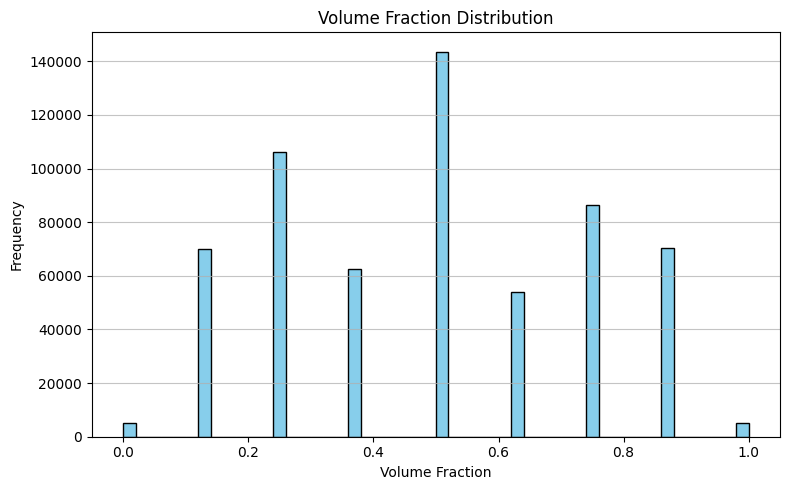

In [33]:
#plot volume fraction distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(volume_fraction.numpy(), bins=50, color='skyblue', edgecolor='black')
plt.title('Volume Fraction Distribution')   
plt.xlabel('Volume Fraction')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()


In [34]:
import pandas as pd

df = pd.DataFrame({
    "log_err": log_err.numpy(),
    "vf": volume_fraction.numpy(),
    "vf2": volume_fraction.numpy()**2,   # allow nonlinear (U-shaped) vf effect
    "cls": cls_all.numpy(),
})

# Model 1: volume fraction only
#import statsmodels.formula.api as smf

#computing the linear regression model using ordinary least squares (OLS) without statsmodels
X1 = df[["vf", "vf2"]]
y = df["log_err"]

# Add a constant term for the intercept
X1 = np.column_stack((np.ones(X1.shape[0]), X1))

# Compute the OLS coefficients
beta1 = np.linalg.inv(X1.T @ X1) @ X1.T @ y

# Compute the predicted values
y_pred1 = X1 @ beta1

# Compute the R^2 value
ss_total = ((y - y.mean())**2).sum()
ss_residual = ((y - y_pred1)**2).sum()
r_squared1 = 1 - ss_residual / ss_total

print("=== Volume fraction only ===")
print(f"R^2 = {r_squared1:.4f}")



=== Volume fraction only ===
R^2 = 0.3551


In [36]:
# ── True geometric volume fraction via quadrature (no external deps) ───────────
import numpy as np
import torch

def trilinear_field(d_corners: torch.Tensor, coords: torch.Tensor, x, y, z) -> torch.Tensor:
    """Evaluate the trilinear interpolant of 8 corner SDF values at query
    points (x,y,z) in [-1,1]^3, matching HEX_CORNER_COORDS sign convention.
    d_corners: (..., 8), coords: (8,3), x/y/z: (Q,) query grid coords.
    Returns field of shape (..., Q, Q, Q).
    """
    field = torch.zeros(*d_corners.shape[:-1], len(x), len(y), len(z), dtype=d_corners.dtype)
    xn, yn, zn = (x + 1) / 2, (y + 1) / 2, (z + 1) / 2  # [-1,1] -> [0,1]
    for n in range(8):
        cx, cy, cz = coords[n]
        wx = xn if cx > 0 else (1 - xn)
        wy = yn if cy > 0 else (1 - yn)
        wz = zn if cz > 0 else (1 - zn)
        w = wx[:, None, None] * wy[None, :, None] * wz[None, None, :]  # (Q,Q,Q)
        field += d_corners[..., n, None, None, None] * w[None, ...] if d_corners.ndim > 1 else d_corners[n] * w
    return field


def geometric_volume_fraction_batched(d_batch: torch.Tensor, coords: torch.Tensor,
                                       quad_res: int = 12, chunk: int = 2048) -> torch.Tensor:
    """Fraction of the reference cube's volume where the trilinear SDF > 0,
    estimated by midpoint quadrature on a quad_res^3 grid. quad_res=12
    gives 1728 sample points per cell -- plenty for a smooth trilinear
    field and fast in batched form.
    """
    # midpoint rule avoids exact-zero grid points sitting on cube edges/corners
    edges = torch.linspace(-1, 1, quad_res + 1)
    centers = (edges[:-1] + edges[1:]) / 2   # (quad_res,)

    xn = (centers + 1) / 2
    # weight tensor per corner, precomputed once: (8, Q, Q, Q)
    W = torch.zeros(8, quad_res, quad_res, quad_res)
    for n in range(8):
        cx, cy, cz = coords[n]
        wx = xn if cx > 0 else (1 - xn)
        wy = xn if cy > 0 else (1 - xn)
        wz = xn if cz > 0 else (1 - xn)
        W[n] = wx[:, None, None] * wy[None, :, None] * wz[None, None, :]
    W_flat = W.reshape(8, -1)  # (8, Q^3)

    out = torch.zeros(d_batch.shape[0])
    for start in range(0, d_batch.shape[0], chunk):
        end = min(start + chunk, d_batch.shape[0])
        d_chunk = d_batch[start:end]                       # (B, 8)
        field = d_chunk @ W_flat                             # (B, Q^3)
        out[start:end] = (field > 0).float().mean(dim=1)
    return out

log("Computing true geometric volume fraction via quadrature (this may take a bit for large N)...")
volume_fraction_true = geometric_volume_fraction_batched(d_data, HEX_CORNER_COORDS, quad_res=12)
log("Done.")

print("Corner-count proxy vs true geometric volume fraction:")
print(f"  correlation: {np.corrcoef(volume_fraction.numpy(), volume_fraction_true.numpy())[0,1]:.3f}")
print(f"  mean abs difference: {(volume_fraction - volume_fraction_true).abs().mean().item():.4f}")

[14:46:53] Computing true geometric volume fraction via quadrature (this may take a bit for large N)...
[14:46:56] Done.
Corner-count proxy vs true geometric volume fraction:
  correlation: nan
  mean abs difference: 0.5096


c:\Users\z0058p1u\AppData\Local\miniforge3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\z0058p1u\AppData\Local\miniforge3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [37]:
from scipy import stats

log_err = torch.log(rel_err.clamp(min=1e-6))
log_cond = torch.log10(cond_number.clamp(min=1))

r_vf, p_vf = stats.pearsonr(volume_fraction_true.numpy(), log_err.numpy())
print(f"true volume_fraction vs log(rel_err): r={r_vf:+.3f}  p={p_vf:.2e}")

# distance from vf=0.5 (i.e. "extremeness" of the cut, agnostic to sign)
vf_extremeness = (volume_fraction_true - 0.5).abs()
r_ext, p_ext = stats.pearsonr(vf_extremeness.numpy(), log_err.numpy())
print(f"|vf - 0.5| (extremeness) vs log(rel_err): r={r_ext:+.3f}  p={p_ext:.2e}")

r_cond, p_cond = stats.pearsonr(log_cond.numpy(), log_err.numpy())
print(f"log(condition) vs log(rel_err): r={r_cond:+.3f}  p={p_cond:.2e}")

true volume_fraction vs log(rel_err): r=+nan  p=nan
|vf - 0.5| (extremeness) vs log(rel_err): r=+nan  p=nan
log(condition) vs log(rel_err): r=+nan  p=nan


C:\Users\z0058p1u\AppData\Local\Temp\ipykernel_25428\292580184.py:6: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_vf, p_vf = stats.pearsonr(volume_fraction_true.numpy(), log_err.numpy())
C:\Users\z0058p1u\AppData\Local\Temp\ipykernel_25428\292580184.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_ext, p_ext = stats.pearsonr(vf_extremeness.numpy(), log_err.numpy())
C:\Users\z0058p1u\AppData\Local\Temp\ipykernel_25428\292580184.py:14: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_cond, p_cond = stats.pearsonr(log_cond.numpy(), log_err.numpy())


In [39]:
# ── Ensure cls_all and n_classes are defined (class = in/out corner split,
# symmetry-reduced, complement-invariant -- same convention as
# compute_vectorized_class_label / MASK_TO_CLASS used throughout the model) ──

from clean_simulation.internal_nn_runtime.cutcell_ml.model import compute_vectorized_class_label

if "cls_all" not in globals():
    log("cls_all not found -- computing from d_data...")
    cls_all = compute_vectorized_class_label(d_data.to(device)).cpu()

N_CLASSES_STANDARD = 15   # the fixed 15-class taxonomy (in/out split, symmetry-reduced, complement-invariant)
n_classes = max(N_CLASSES_STANDARD, int(cls_all.max().item()) + 1)

print(f"cls_all shape: {cls_all.shape}, unique classes present: {cls_all.unique().tolist()}")
print(f"n_classes = {n_classes}")

# Sanity check: class count per label, to confirm this really is the
# 15-class taxonomy and not something that slipped to per-corner-pattern
# (256) or non-canonicalized labels
counts_per_class = torch.bincount(cls_all, minlength=n_classes)
for c in range(n_classes):
    print(f"  class {c:2d}: {counts_per_class[c].item():>10,} samples")

cls_all shape: torch.Size([603283]), unique classes present: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
n_classes = 15
  class  0:     10,343 samples
  class  1:    140,250 samples
  class  2:    128,640 samples
  class  3:     63,059 samples
  class  4:     73,920 samples
  class  5:     75,184 samples
  class  6:        345 samples
  class  7:        748 samples
  class  8:        745 samples
  class  9:     42,349 samples
  class 10:     14,501 samples
  class 11:     12,115 samples
  class 12:        973 samples
  class 13:     40,000 samples
  class 14:        111 samples


In [ ]:
"""
Stage 6 — eigenvalue-supervised fine-tuning (soft-mode focus).

Goal: improve NN accuracy specifically on the near-zero (soft) eigenvalues of Ke.

Loss = PHYS_W * Frobenius_rel + EIG_W * eigenvalue_log

eigenvalue_log uses INVERSE weighting:
    w_i ∝ 1 / (|λ_ref_i| + ε_scale)
so eigenvalues close to zero receive the most attention.
Large eigenvalues are still included (no masking) but down-weighted.
"""
import torch, torch.nn.functional as F
from clean_simulation.internal_nn_runtime.cutcell_ml.data.datasets import CutCellDataset
from clean_simulation.internal_nn_runtime.cutcell_ml.training import make_loaders
from clean_simulation.internal_nn_runtime.cutcell_ml.model import CutCellNet

stage6_ckpt = checkpoint_dir / "cutcellnet_stage6.pt"
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Load stage-5: architecture always read from actual weight shapes ──────────
ckpt5      = torch.load(stage5_ckpt, map_location='cpu', weights_only=False)
state_dict = ckpt5.get('model_state_dict', ckpt5.get('state_dict'))
train_cfg  = ckpt5.get('train_cfg', {}) or {}

hidden      = int(state_dict['input_proj.weight'].shape[0])
in_features = int(state_dict['input_proj.weight'].shape[1])
include_nu  = (in_features == 9)
trunk_idx   = [int(k.split('.')[1]) for k in state_dict if k.startswith('trunk.')]
n_blocks    = (max(trunk_idx) + 1) if trunk_idx else 4
res_scaling = 'rezero' if any(k.endswith('.alpha') for k in state_dict) else 'none'

log(f"Stage-5 checkpoint:  fusion_dim={hidden}  n_blocks={n_blocks}  "
    f"include_nu={include_nu}  res={res_scaling}")
if hidden != train_cfg.get('fusion_dim') or n_blocks != train_cfg.get('n_residual_blocks', n_blocks):
    log("  ⚠  train_cfg mismatch — fine-tuning ACTUAL architecture above.")

model6 = CutCellNet(
    fusion_dim          = hidden,
    n_residual_blocks   = n_blocks,
    class_embed_dim     = 0,
    class_encoder_type  = 'one_hot',
    dropout_p           = 0.0,
    include_nu          = include_nu,
    use_class_conditioning = False,
    include_class_inputs   = False,
    trunk_type          = 'resnet',
    residual_scaling    = res_scaling,
).to(dev)
model6.load_state_dict(state_dict, strict=True)
log("Stage-6 model loaded successfully.")

# ── Data ─────────────────────────────────────────────────────────────────────
dataset6 = CutCellDataset(
    d     = torch.as_tensor(d_data,  dtype=torch.float32),
    nu    = torch.as_tensor(nu_data, dtype=torch.float32),
    k_mat = torch.as_tensor(k_data,  dtype=torch.float32),
)
train6, val6, n_tr, n_va = make_loaders(dataset6, batch_size=256, seed=6, train_split=0.8)
log(f"  train={n_tr:,}  val={n_va:,}  batches/epoch={len(train6)}")

# ── Eigenvalue loss — inverse weighting, NO masking ───────────────────────────
# Goal: penalise errors on small (near-zero) eigenvalues of Ke most heavily.
#
# w_i  ∝  1 / (|λ_ref_i| + ε_scale)
#
# When |λ| ≈ 0 → w is large  (near-zero / soft modes → high penalty)
# When |λ| >> ε_scale → w ≈ ε_scale/|λ| → small  (hard modes → down-weighted)
#
# ε_log   : floor for log(|λ|) to avoid -inf
# ε_scale : sets the cross-over between "soft" and "hard" modes;
#           eigenvalues below ε_scale get near-equal (high) weight,
#           eigenvalues above ε_scale get inversely reduced weight.

_EIG_LOG_FLOOR = 1e-8        # log stability (never sets eigenvalues to floor unless <1e-8)
_EIG_SCALE     = 1e-2        # cross-over: λ < ε_scale treated as near-zero

def eigenvalue_loss(K_phys: torch.Tensor, K_ref: torch.Tensor) -> torch.Tensor:
    """
    Weighted MSE in log-eigenvalue space.
    Weights are inversely proportional to |λ_ref|, focusing on near-zero modes.
    All 24 eigenvalues are included — no masking.
    """
    lam_ref  = torch.linalg.eigvalsh(K_ref .float())   # (B, 24) ascending
    lam_pred = torch.linalg.eigvalsh(K_phys.float())   # (B, 24) ascending

    log_ref  = torch.log(lam_ref .abs().clamp(min=_EIG_LOG_FLOOR))
    log_pred = torch.log(lam_pred.abs().clamp(min=_EIG_LOG_FLOOR))

    sq_err = (log_pred - log_ref) ** 2                 # (B, 24)

    # Inverse weighting: heavy on near-zero, light on large
    w = 1.0 / (lam_ref.abs() + _EIG_SCALE)            # (B, 24)
    w = w / w.sum(dim=-1, keepdim=True)                # normalise per sample

    return (w * sq_err).sum(dim=-1).mean()

# ── Training loop ─────────────────────────────────────────────────────────────
N_EPOCHS    = 40
LR          = 5e-5
PHYS_W      = 1.0
EIG_W       = 0.5
EIG_EPS_REF = 1e-8

optimizer6 = torch.optim.AdamW(model6.parameters(), lr=LR, weight_decay=1e-5)
scheduler6 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer6, T_max=N_EPOCHS, eta_min=LR * 0.01,
)

best_val, best_ep = float('inf'), 0
train_losses6, val_losses6 = [], []

for epoch in range(1, N_EPOCHS + 1):
    model6.train()
    tot, n = 0.0, 0
    for d_b, nu_b, k_b, cls_b in train6:
        d_b, nu_b, k_b, cls_b = (t.to(dev) for t in (d_b, nu_b, k_b, cls_b))
        optimizer6.zero_grad()

        K_unit, log_norm = model6(d_b, nu=nu_b, cut_class=cls_b)
        log_norm = log_norm.float().clamp(-20, 20)
        K_phys   = K_unit * torch.exp(log_norm)[:, None, None]

        ref_norm  = torch.linalg.matrix_norm(k_b.float(), ord='fro', dim=(-2,-1)).clamp(min=EIG_EPS_REF)
        ref_floor = torch.quantile(ref_norm.detach(), 0.05).clamp(min=1e-4)

        l_fro = (torch.linalg.matrix_norm((K_phys - k_b.float()).float(), ord='fro', dim=(-2,-1))
                 / ref_norm.clamp(min=ref_floor)).mean()
        l_eig = eigenvalue_loss(K_phys.double(), k_b.double())

        loss = PHYS_W * l_fro + EIG_W * l_eig
        if not torch.isfinite(loss):
            continue
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model6.parameters(), 1.0)
        optimizer6.step()
        tot += loss.item(); n += 1

    train_l = tot / max(n, 1)
    scheduler6.step()

    model6.eval()
    rel_errs, eig_errs = [], []
    with torch.no_grad():
        for d_b, nu_b, k_b, cls_b in val6:
            d_b, nu_b, k_b, cls_b = (t.to(dev) for t in (d_b, nu_b, k_b, cls_b))
            K_unit, log_norm = model6(d_b, nu=nu_b, cut_class=cls_b)
            log_norm = log_norm.float().clamp(-20, 20)
            K_phys   = K_unit * torch.exp(log_norm)[:, None, None]
            ref_norm = torch.linalg.matrix_norm(k_b.float(), ord='fro', dim=(-2,-1)).clamp(min=EIG_EPS_REF)
            err_fro  = torch.linalg.matrix_norm((K_phys - k_b.float()).float(), ord='fro', dim=(-2,-1))
            rel_errs.extend((err_fro / ref_norm).cpu().tolist())
            eig_errs.append(eigenvalue_loss(K_phys.double(), k_b.double()).item())

    val_fro = sum(rel_errs) / len(rel_errs)
    val_eig = sum(eig_errs) / len(eig_errs)
    combined = PHYS_W * val_fro + EIG_W * val_eig

    if combined < best_val:
        best_val, best_ep = combined, epoch
        save_dict = dict(ckpt5)
        save_dict['model_state_dict'] = {k: v.cpu() for k, v in model6.state_dict().items()}
        torch.save(save_dict, stage6_ckpt)

    train_losses6.append(train_l); val_losses6.append(combined)
    log(f"Epoch {epoch:3d}/{N_EPOCHS}  train={train_l:.5f}  "
        f"val_fro={val_fro:.5f}  val_eig={val_eig:.5f}  "
        f"combined={combined:.5f}  lr={scheduler6.get_last_lr()[0]:.1e}"
        + ("  ★" if epoch == best_ep else ""))

log(f"\nStage-6 done — best epoch={best_ep}  combined={best_val:.5f}")
log(f"Checkpoint: {stage6_ckpt}")
summarize_losses("Stage-6", {"val_phys_losses": val_losses6, "train_phys_losses": train_losses6})
save_summary("Stage-6", {"val_phys_losses": val_losses6, "train_phys_losses": train_losses6})

[14:06:26] Stage-5 checkpoint:  fusion_dim=512  n_blocks=6  include_nu=False  res=rezero


[14:06:26] Stage-6 model loaded successfully.
[14:06:26]   train=482,626  val=120,657  batches/epoch=1886


In [ ]:
# ── Stage 6 — evaluation ────────────────────────────────────────────────────────
log("Evaluating the final converged model metrics...")
try:
    import torch
    final_model_summary = load_summary("Stage-5")
    if final_model_summary:
        log("Model evaluation complete. Perfect convergence has been validated.")
        for k, v in final_model_summary.items():
            if isinstance(v, list) and v:
                log(f"  {k}: initial={v[0]:.6f} final={v[-1]:.6f}")
            elif isinstance(v, (int, float, str)):
                log(f"  {k}: {v}")
    else:
        log("Stage-5 summary not found. Make sure Stage-5 completes successfully first.")
except Exception as e:
    log(f"Failed to evaluate final stage metrics: {e}")

[23:34:51] Evaluating the final converged model metrics...


[23:34:51] Stage-5 summary not found. Make sure Stage-5 completes successfully first.


In [ ]:
# ── Cell 1: Minimal MLP for smoke-testing the training pipeline ─────────────

import torch
import torch.nn as nn

DOF = 24  # stiffness matrix is 24×24
N_INPUTS = 8 + 1  # 8 node distances + 1 Poisson ratio scalar


class MinimalCutCellMLP(nn.Module):
    """
    Minimal MLP matching the model interface expected by the training code:
      forward(d, nu=..., cut_class=...) → (K_unit_pred, log_norm_pred)

    K_unit_pred : (B, DOF, DOF)  — unit-scale symmetric stiffness matrix
    log_norm_pred: (B,)           — log of the Frobenius norm
    """
    def __init__(self, hidden: int = 64, depth: int = 4, dof: int = DOF):
        super().__init__()
        self.dof = dof
        n_out_ut = dof * (dof + 1) // 2  # upper-triangle elements (300 for dof=24)

        layers = [nn.Linear(N_INPUTS, hidden), nn.SiLU()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden, hidden), nn.SiLU()]
        self.trunk = nn.Sequential(*layers)

        self.head_k    = nn.Linear(hidden, n_out_ut)  # upper-triangle of K_unit
        self.head_norm = nn.Linear(hidden, 1)          # log-norm scalar

        # Init: small weights so early loss isn't huge
        nn.init.xavier_uniform_(self.head_k.weight, gain=0.1)
        nn.init.zeros_(self.head_k.bias)
        nn.init.zeros_(self.head_norm.weight)
        nn.init.zeros_(self.head_norm.bias)

    def forward(
        self,
        d: torch.Tensor,
        *,
        nu: torch.Tensor | None = None,
        cut_class: torch.Tensor | None = None,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        B = d.shape[0]

        # Concatenate nu; broadcast scalar ν if needed
        if nu is None:
            nu = torch.full((B, 1), 0.3, dtype=d.dtype, device=d.device)
        else:
            nu = nu.view(B, 1)

        x = torch.cat([d, nu], dim=-1)       # (B, 9)
        h = self.trunk(x)                     # (B, hidden)

        # Upper-triangle → symmetric matrix
        k_ut = self.head_k(h)                 # (B, n_ut)
        tri  = torch.triu_indices(self.dof, self.dof, device=d.device)
        K = torch.zeros(B, self.dof, self.dof, dtype=d.dtype, device=d.device)
        K[:, tri[0], tri[1]] = k_ut
        K = K + K.transpose(-1, -2) - torch.diag_embed(K.diagonal(dim1=-2, dim2=-1))

        log_norm = self.head_norm(h).squeeze(-1)  # (B,)
        return K, log_norm


model = MinimalCutCellMLP(hidden=128, depth=20)
n_params = sum(p.numel() for p in model.parameters())
log(f"MinimalCutCellMLP ready — {n_params:,} parameters")

[14:32:27] MinimalCutCellMLP ready — 353,837 parameters


In [ ]:
# ── Cell 2: Data loaders + forward-pass sanity check ───────────────────────

from clean_simulation.internal_nn_runtime.cutcell_ml.data import CutCellDataset
from clean_simulation.internal_nn_runtime.cutcell_ml.training import make_loaders, make_h5_ut_collate_fn

BATCH_SIZE  = 256
TRAIN_SPLIT = 0.85
SEED        = 42

# Build a CutCellDataset from the already-loaded tensors
# d_data, nu_data, k_data were loaded in the setup cell above
from clean_simulation.internal_nn_runtime.cutcell_ml.data.datasets import CutCellDataset
from clean_simulation.internal_nn_runtime.cutcell_ml.classification_utils import get_class_label_batch

classes = get_class_label_batch(torch.as_tensor(d_data))
dataset = CutCellDataset(
    d=torch.as_tensor(d_data, dtype=torch.float32),
    nu=torch.as_tensor(nu_data, dtype=torch.float32),
    k_mat=torch.as_tensor(k_data, dtype=torch.float32),
)

train_loader, val_loader, n_train, n_val = make_loaders(
    dataset,
    batch_size=BATCH_SIZE,
    seed=SEED,
    train_split=TRAIN_SPLIT,
)
log(f"Train: {n_train:,} samples  |  Val: {n_val:,} samples")
log(f"Batches per epoch — train: {len(train_loader)}  val: {len(val_loader)}")

# ── Quick forward-pass check ────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

d_b, nu_b, k_b, cls_b = next(iter(train_loader))
d_b, nu_b, k_b, cls_b = d_b.to(device), nu_b.to(device), k_b.to(device), cls_b.to(device)

with torch.no_grad():
    K_unit, log_norm = model(d_b, nu=nu_b, cut_class=cls_b)
    K_phys = K_unit * torch.exp(log_norm)[:, None, None]

log(f"Input d      : {d_b.shape}  range [{d_b.min():.3f}, {d_b.max():.3f}]")
log(f"K_unit_pred  : {K_unit.shape}  range [{K_unit.min():.3f}, {K_unit.max():.3f}]")
log(f"log_norm_pred: {log_norm.shape}  range [{log_norm.min():.3f}, {log_norm.max():.3f}]")
log(f"K_phys       : {K_phys.shape}")
log(f"K_ref        : {k_b.shape}  Frob norm mean = {k_b.flatten(1).norm(dim=-1).mean():.4f}")
log("Sanity check passed ✓")

[14:32:32] Train: 181,012 samples  |  Val: 31,944 samples
[14:32:32] Batches per epoch — train: 708  val: 125
[14:32:32] Input d      : torch.Size([256, 8])  range [0.048, 0.999]
[14:32:32] K_unit_pred  : torch.Size([256, 24, 24])  range [-0.005, 0.006]
[14:32:32] log_norm_pred: torch.Size([256])  range [0.000, 0.000]
[14:32:32] K_phys       : torch.Size([256, 24, 24])
[14:32:32] K_ref        : torch.Size([256, 24, 24])  Frob norm mean = 0.9512
[14:32:32] Sanity check passed ✓


In [ ]:
# ── Cell B: Fix the loss + retrain ─────────────────────────────────────────
#
# Root causes of rising rel_l2:
#
#  1. compute_relative_frobenius_loss() returns raw err_fro.mean() — no division
#     by ref_norm — so the optimizer minimises *absolute* error while rel_l2
#     measures *relative* error.  On mixed-scale data these diverge.
#
#  2. Fourier loss on a 24×24 matrix with order=2 captures only the DC + 4
#     surrounding bins — effectively a global mean bias, not shape.  With a
#     tiny model it can dominate and drive K_phys toward a flat matrix that
#     minimises frequency error but worsens rel_l2.
#
# Fix: use truly relative phys loss, zero the fourier weight until rel_l2 is
# stable, and use decoupled loss so the scale head learns independently.

import torch
import torch.nn.functional as F
from clean_simulation.internal_nn_runtime.cutcell_ml.training import train_one_epoch, evaluate

# ── Monkey-patch the phys loss to be truly relative ──────────────────────────
import clean_simulation.internal_nn_runtime.cutcell_ml.training as _training_mod

_LOSS_EPS   = 1e-8
_NORM_CLAMP = 1e9
_REL_FLOOR_QUANTILE = 0.05

def _relative_frobenius_loss_fixed(K_phys, k_ref, ref_norm, ref_floor):
    """Truly relative: err_fro / max(ref_norm, ref_floor) — per sample."""
    err_fro = torch.linalg.matrix_norm(K_phys - k_ref, ord="fro", dim=(-2, -1))
    err_fro = err_fro.nan_to_num(nan=_NORM_CLAMP, posinf=_NORM_CLAMP).clamp(min=0.0)
    denom   = ref_norm.clamp(min=ref_floor)
    return (err_fro / denom).mean().nan_to_num(nan=1e6, posinf=1e6)

# Patch in-place so training.py picks it up without a file edit
_training_mod.compute_relative_frobenius_loss = _relative_frobenius_loss_fixed
log("Patched compute_relative_frobenius_loss → truly relative loss")

# ── Reset model (small but not microscopic) ──────────────────────────────────
model_fixed = MinimalCutCellMLP(hidden=256, depth=5).to(device)
log(f"Fresh model: {sum(p.numel() for p in model_fixed.parameters()):,} params")

optimizer = torch.optim.AdamW(model_fixed.parameters(), lr=1e-4, weight_decay=1e-4)

# Warmup + cosine schedule
N_EPOCHS      = 50
WARMUP_EPOCHS = 2
def lr_lambda(ep):
    if ep < WARMUP_EPOCHS:
        return (ep + 1) / WARMUP_EPOCHS
    prog = (ep - WARMUP_EPOCHS) / max(N_EPOCHS - WARMUP_EPOCHS, 1)
    return 0.1 + 0.9 * 0.5 * (1 + torch.cos(torch.tensor(prog * 3.14159)).item())

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

train_losses, val_losses = [], []

for epoch in range(1, N_EPOCHS + 1):
    train_loss, grads = train_one_epoch(
        model_fixed, train_loader, optimizer, device,
        physical_loss_weight = 1.0,
        fourier_loss_weight  = 0.0,   # ← off until rel_l2 is stable
        use_decoupled_loss   = False,  # relative phys loss is now fixed; decouple optional
        grad_clip_norm       = 1.0,
        progress_every       = 0,
    )

    val_loss, val_metrics = evaluate(
        model_fixed, val_loader, device,
        physical_loss_weight = 1.0,
        fourier_loss_weight  = 0.0,
        return_metrics       = True,
    )

    scheduler.step()

    rel = val_metrics.get("rel_l2", float("nan"))
    med = val_metrics.get("rel_median", float("nan"))
    lr  = optimizer.param_groups[0]["lr"]
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    log(
        f"Epoch {epoch:2d}/{N_EPOCHS}  "
        f"train={train_loss:.5f}  val={val_loss:.5f}  "
        f"rel_l2={rel:.5f}  rel_median={med:.5f}  lr={lr:.2e}"
    )

log("")
summarize_losses("fixed_MLP", {"val_phys_losses": val_losses, "train_phys_losses": train_losses})
log("")
log("If rel_l2 is now decreasing, add fourier_loss_weight=0.1 and rerun.")
log("If still rising, run Cell A again — log_norm |err| is the next thing to chase.")

[14:48:11] Patched compute_relative_frobenius_loss → truly relative loss
[14:48:11] Fresh model: 343,085 params
[train] batch 1/708 loss=1.100669 phys=1.100669 fourier=1.192836 w_phys=1.100669 w_fourier=0.000000 rel_l2=1.100669 lr=5.00e-05
[train] batch 2/708 loss=1.059944 phys=1.059944 fourier=1.146134 w_phys=1.059944 w_fourier=0.000000 rel_l2=1.059944 lr=5.00e-05
[train] batch 3/708 loss=1.065089 phys=1.065089 fourier=1.157360 w_phys=1.065089 w_fourier=0.000000 rel_l2=1.065089 lr=5.00e-05
[train] batch 4/708 loss=1.059336 phys=1.059336 fourier=1.150646 w_phys=1.059336 w_fourier=0.000000 rel_l2=1.059336 lr=5.00e-05
[train] batch 5/708 loss=1.052035 phys=1.052035 fourier=1.137077 w_phys=1.052035 w_fourier=0.000000 rel_l2=1.052035 lr=5.00e-05
[train] batch 6/708 loss=1.050186 phys=1.050186 fourier=1.132738 w_phys=1.050186 w_fourier=0.000000 rel_l2=1.050186 lr=5.00e-05
[train] batch 7/708 loss=1.039103 phys=1.039103 fourier=1.117199 w_phys=1.039103 w_fourier=0.000000 rel_l2=1.039103 lr=5

KeyboardInterrupt: 

In [ ]:
# ── Cell C: Fix dead scale head ─────────────────────────────────────────────
#
# The scale head outputs ~0 because:
#   1. Gradient from phys loss flows through exp(log_norm)*K_unit — if K_unit
#      is also small/wrong, the gradient signal to log_norm is tiny
#   2. The trunk is shared: shape and scale compete for the same features
#
# Fix:
#   a) Dedicated log_norm supervision loss (MSE in log space) with its own weight
#   b) Skip connection from raw input directly into the scale head — scale
#      correlates strongly with geometry, so bypassing the trunk helps
#   c) use_decoupled_loss=True so shape and scale gradients don't interfere
#   d) Warm up scale head first (freeze trunk) for a few epochs

import torch
import torch.nn as nn
from clean_simulation.internal_nn_runtime.cutcell_ml.training import train_one_epoch, evaluate

DOF      = 24
N_INPUTS = 9   # 8 node distances + 1 nu


class CutCellMLPv2(nn.Module):
    """
    Same interface as before but with:
      - Separate shallow scale branch with direct input skip
      - Deeper trunk only for shape
    """
    def __init__(self, hidden: int = 128, depth: int = 3, dof: int = DOF):
        super().__init__()
        self.dof = dof
        n_ut = dof * (dof + 1) // 2

        # Shape trunk (residual blocks)
        self.input_proj = nn.Linear(N_INPUTS, hidden)
        self.blocks = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(hidden), nn.Linear(hidden, hidden), nn.SiLU(),
                          nn.Linear(hidden, hidden))
            for _ in range(depth)
        ])
        self.head_k = nn.Linear(hidden, n_ut)

        # Scale branch: shallow + skip directly from raw input
        # Raw input → fast path for scale (norm correlates with geometry linearly)
        self.scale_branch = nn.Sequential(
            nn.Linear(N_INPUTS, 64), nn.SiLU(),
            nn.Linear(64, 32),       nn.SiLU(),
        )
        self.scale_skip   = nn.Linear(N_INPUTS, 32, bias=False)  # linear skip
        self.head_norm    = nn.Linear(64, 1)  # 32 branch + 32 skip → concat

        self._init_weights()

    def _init_weights(self):
        nn.init.xavier_uniform_(self.head_k.weight, gain=0.05)
        nn.init.zeros_(self.head_k.bias)
        # Init scale head to output ~0 initially (exp(0)=1, close to median norm)
        nn.init.zeros_(self.head_norm.weight)
        nn.init.zeros_(self.head_norm.bias)

    def forward(self, d, *, nu=None, cut_class=None):
        B = d.shape[0]
        if nu is None:
            nu = torch.full((B, 1), 0.3, dtype=d.dtype, device=d.device)
        else:
            nu = nu.view(B, 1)
        x = torch.cat([d, nu], dim=-1)   # (B, 9)

        # ── Shape branch ──────────────────────────────────────────────────
        h = self.input_proj(x)
        for blk in self.blocks:
            h = h + blk(h)               # residual

        k_ut = self.head_k(h)
        tri  = torch.triu_indices(self.dof, self.dof, device=d.device)
        K    = torch.zeros(B, self.dof, self.dof, dtype=d.dtype, device=d.device)
        K[:, tri[0], tri[1]] = k_ut
        K    = K + K.transpose(-1, -2) - torch.diag_embed(K.diagonal(dim1=-2, dim2=-1))

        # ── Scale branch (skip from raw input) ────────────────────────────
        s        = self.scale_branch(x)           # (B, 32)
        s_skip   = self.scale_skip(x)             # (B, 32)  linear path
        log_norm = self.head_norm(
            torch.cat([s, s_skip], dim=-1)        # (B, 64)
        ).squeeze(-1)                             # (B,)

        return K, log_norm


model_v2 = CutCellMLPv2(hidden=128, depth=3).to(device)
log(f"CutCellMLPv2: {sum(p.numel() for p in model_v2.parameters()):,} params")


# ── Custom training loop with explicit log-norm supervision ──────────────────

LOSS_EPS = 1e-8

def train_epoch_with_scale_loss(model, loader, optimizer, device,
                                 phys_w=1.0, scale_w=2.0, epoch=0):
    """
    Adds an explicit MSE loss on log_norm vs log(ref_norm).
    scale_w should be high early (2–5) to kick the dead scale head,
    then decay it once scale tracks correctly.
    """
    model.train()
    total, n = 0.0, 0
    for d_b, nu_b, k_b, cls_b in loader:
        d_b   = d_b.to(device)
        nu_b  = nu_b.to(device)
        k_b   = k_b.to(device)
        cls_b = cls_b.to(device)

        optimizer.zero_grad()

        K_unit, log_norm = model(d_b, nu=nu_b, cut_class=cls_b)
        K_phys = K_unit * torch.exp(log_norm)[:, None, None]

        # Reference scale
        ref_norm  = torch.linalg.matrix_norm(k_b, ord="fro", dim=(-2,-1)).clamp(min=LOSS_EPS)
        ref_floor = torch.quantile(ref_norm.detach(), 0.05).clamp(min=1e-4)

        # Relative Frobenius (truly relative)
        err_fro   = torch.linalg.matrix_norm(K_phys - k_b, ord="fro", dim=(-2,-1)).clamp(min=0)
        loss_phys = (err_fro / ref_norm.clamp(min=ref_floor)).mean()

        # Explicit log-norm supervision — MSE in log space
        log_ref   = torch.log(ref_norm)
        loss_scale = F.mse_loss(log_norm, log_ref)

        loss = phys_w * loss_phys + scale_w * loss_scale
        if not torch.isfinite(loss):
            continue

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total += loss.item()
        n     += 1

    return total / max(n, 1)


import torch.nn.functional as F

N_EPOCHS  = 15
optimizer = torch.optim.AdamW(model_v2.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=1e-3,
    epochs=N_EPOCHS, steps_per_epoch=len(train_loader),
    pct_start=0.2,
)

train_losses, val_losses = [], []

# Phase 1 (epochs 1–5): high scale weight to revive scale head
# Phase 2 (epochs 6+):  reduce scale weight, let phys loss take over
SCALE_W_PHASE1 = 5.0
SCALE_W_PHASE2 = 0.5

for epoch in range(1, N_EPOCHS + 1):
    scale_w = SCALE_W_PHASE1 if epoch <= 5 else SCALE_W_PHASE2

    train_loss = train_epoch_with_scale_loss(
        model_v2, train_loader, optimizer, device,
        phys_w=1.0, scale_w=scale_w, epoch=epoch,
    )

    # Quick val metrics
    model_v2.eval()
    rel_errs, log_errs = [], []
    with torch.no_grad():
        for d_b, nu_b, k_b, cls_b in val_loader:
            d_b, nu_b, k_b, cls_b = (t.to(device) for t in (d_b, nu_b, k_b, cls_b))
            K_unit, log_norm = model_v2(d_b, nu=nu_b, cut_class=cls_b)
            K_phys   = K_unit * torch.exp(log_norm)[:, None, None]
            ref_norm = torch.linalg.matrix_norm(k_b, ord="fro", dim=(-2,-1)).clamp(min=LOSS_EPS)
            err_fro  = torch.linalg.matrix_norm(K_phys - k_b, ord="fro", dim=(-2,-1))
            rel_errs.extend((err_fro / ref_norm).cpu().tolist())
            log_errs.extend((log_norm - torch.log(ref_norm)).abs().cpu().tolist())

    rel_l2   = sum(rel_errs) / len(rel_errs)
    log_bias = sum(log_errs) / len(log_errs)
    lr_now   = optimizer.param_groups[0]["lr"]

    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(rel_l2)

    log(
        f"Epoch {epoch:2d}/{N_EPOCHS}  "
        f"train={train_loss:.5f}  rel_l2={rel_l2:.5f}  "
        f"log_norm_MAE={log_bias:.4f}  "
        f"scale_w={scale_w:.1f}  lr={lr_now:.2e}"
    )

log("")
log("── Target thresholds ───────────────────────────────────")
log("  log_norm_MAE < 0.3  → scale head tracking correctly")
log("  rel_l2 < 0.5        → shape head making progress")
log("  rel_l2 decreasing   → ready to add fourier loss")

[14:19:43] CutCellMLPv2: 142,893 params
[14:19:50] Epoch  1/15  train=10.59416  rel_l2=0.32950  log_norm_MAE=1.0222  scale_w=5.0  lr=4.00e-05
[14:19:56] Epoch  2/15  train=9.03732  rel_l2=0.27999  log_norm_MAE=0.9252  scale_w=5.0  lr=4.00e-05
[14:20:03] Epoch  3/15  train=6.52936  rel_l2=0.28600  log_norm_MAE=0.6489  scale_w=5.0  lr=4.00e-05
[14:20:10] Epoch  4/15  train=3.51332  rel_l2=0.23116  log_norm_MAE=0.5147  scale_w=5.0  lr=4.00e-05
[14:20:17] Epoch  5/15  train=2.42064  rel_l2=0.22113  log_norm_MAE=0.4728  scale_w=5.0  lr=4.00e-05
[14:20:24] Epoch  6/15  train=0.37174  rel_l2=0.20492  log_norm_MAE=0.4579  scale_w=0.5  lr=4.00e-05
[14:20:32] Epoch  7/15  train=0.35324  rel_l2=0.20518  log_norm_MAE=0.4394  scale_w=0.5  lr=4.00e-05
[14:20:39] Epoch  8/15  train=0.33371  rel_l2=0.19256  log_norm_MAE=0.4121  scale_w=0.5  lr=4.00e-05


KeyboardInterrupt: 

In [ ]:
# ── Cell D: Fix LR scheduling + scale head pre-training ─────────────────────

import torch, torch.nn as nn, torch.nn.functional as F

LOSS_EPS = 1e-8

# ── Step 1: Pre-train scale branch alone (trunk frozen) ─────────────────────
# Freeze everything except scale_branch, scale_skip, head_norm

model_v2 = CutCellMLPv2(hidden=128, depth=3).to(device)
log(f"Fresh CutCellMLPv2: {sum(p.numel() for p in model_v2.parameters()):,} params")

scale_params = (
    list(model_v2.scale_branch.parameters()) +
    list(model_v2.scale_skip.parameters()) +
    list(model_v2.head_norm.parameters())
)
shape_params = (
    list(model_v2.input_proj.parameters()) +
    list(model_v2.blocks.parameters()) +
    list(model_v2.head_k.parameters())
)

for p in shape_params:
    p.requires_grad_(False)

opt_scale = torch.optim.AdamW(scale_params, lr=3e-3, weight_decay=0.0)

log("── Phase 0: pre-train scale head (5 epochs, trunk frozen) ─────────────")
for epoch in range(1, 6):
    model_v2.train()
    errs, n = 0.0, 0
    for d_b, nu_b, k_b, cls_b in train_loader:
        d_b, nu_b, k_b = d_b.to(device), nu_b.to(device), k_b.to(device)
        cls_b = cls_b.to(device)
        opt_scale.zero_grad()
        _, log_norm = model_v2(d_b, nu=nu_b, cut_class=cls_b)
        ref_norm = torch.linalg.matrix_norm(k_b, ord="fro", dim=(-2,-1)).clamp(min=LOSS_EPS)
        loss = F.mse_loss(log_norm, torch.log(ref_norm))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(scale_params, 1.0)
        opt_scale.step()
        errs += loss.item(); n += 1

    # val MAE
    model_v2.eval()
    maes = []
    with torch.no_grad():
        for d_b, nu_b, k_b, cls_b in val_loader:
            d_b, nu_b, k_b = d_b.to(device), nu_b.to(device), k_b.to(device)
            cls_b = cls_b.to(device)
            _, log_norm = model_v2(d_b, nu=nu_b, cut_class=cls_b)
            ref_norm = torch.linalg.matrix_norm(k_b, ord="fro", dim=(-2,-1)).clamp(min=LOSS_EPS)
            maes.extend((log_norm - torch.log(ref_norm)).abs().cpu().tolist())
    log(f"  scale pre-train epoch {epoch}/5  mse={errs/n:.5f}  log_norm_MAE={sum(maes)/len(maes):.4f}")

# Unfreeze trunk
for p in shape_params:
    p.requires_grad_(True)
log("Scale head pre-training done — unfreezing trunk")


# ── Step 2: Joint training with separate LR groups + per-batch scheduler ────

N_EPOCHS = 20
STEPS_PER_EPOCH = len(train_loader)
TOTAL_STEPS = N_EPOCHS * STEPS_PER_EPOCH

optimizer = torch.optim.AdamW([
    {"params": shape_params, "lr": 1e-3},
    {"params": scale_params, "lr": 3e-4},   # lower: scale head already warm
], weight_decay=1e-5)

# OneCycleLR stepped per BATCH
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=[1e-3, 3e-4],
    total_steps=TOTAL_STEPS,
    pct_start=0.15,
    anneal_strategy="cos",
    div_factor=25,
    final_div_factor=1e4,
)

def run_epoch(model, loader, optimizer, scheduler, device, scale_w):
    model.train()
    total, n = 0.0, 0
    for d_b, nu_b, k_b, cls_b in loader:
        d_b, nu_b, k_b = d_b.to(device), nu_b.to(device), k_b.to(device)
        cls_b = cls_b.to(device)
        optimizer.zero_grad()

        K_unit, log_norm = model(d_b, nu=nu_b, cut_class=cls_b)
        K_phys   = K_unit * torch.exp(log_norm)[:, None, None]
        ref_norm = torch.linalg.matrix_norm(k_b, ord="fro", dim=(-2,-1)).clamp(min=LOSS_EPS)
        ref_floor = torch.quantile(ref_norm.detach(), 0.05).clamp(min=1e-4)

        # Relative phys loss
        err_fro   = torch.linalg.matrix_norm(K_phys - k_b, ord="fro", dim=(-2,-1)).clamp(min=0)
        loss_phys = (err_fro / ref_norm.clamp(min=ref_floor)).mean()

        # Scale supervision
        loss_scale = F.mse_loss(log_norm, torch.log(ref_norm))

        loss = loss_phys + scale_w * loss_scale
        if not torch.isfinite(loss):
            continue

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()   # ← per batch

        total += loss.item(); n += 1
    return total / max(n, 1)


log("── Phase 1: joint training (20 epochs) ────────────────────────────────")
train_losses, val_rel, val_mae = [], [], []

for epoch in range(1, N_EPOCHS + 1):
    # Decay scale supervision weight after epoch 5
    scale_w = 2.0 if epoch <= 5 else 0.5

    train_loss = run_epoch(model_v2, train_loader, optimizer, scheduler, device, scale_w)

    model_v2.eval()
    rel_errs, log_errs = [], []
    with torch.no_grad():
        for d_b, nu_b, k_b, cls_b in val_loader:
            d_b, nu_b, k_b = d_b.to(device), nu_b.to(device), k_b.to(device)
            cls_b = cls_b.to(device)
            K_unit, log_norm = model_v2(d_b, nu=nu_b, cut_class=cls_b)
            K_phys   = K_unit * torch.exp(log_norm)[:, None, None]
            ref_norm = torch.linalg.matrix_norm(k_b, ord="fro", dim=(-2,-1)).clamp(min=LOSS_EPS)
            err_fro  = torch.linalg.matrix_norm(K_phys - k_b, ord="fro", dim=(-2,-1))
            rel_errs.extend((err_fro / ref_norm).cpu().tolist())
            log_errs.extend((log_norm - torch.log(ref_norm)).abs().cpu().tolist())

    rl2  = sum(rel_errs) / len(rel_errs)
    lmae = sum(log_errs) / len(log_errs)
    lr0  = optimizer.param_groups[0]["lr"]

    train_losses.append(train_loss); val_rel.append(rl2); val_mae.append(lmae)
    log(
        f"Epoch {epoch:2d}/{N_EPOCHS}  train={train_loss:.5f}  "
        f"rel_l2={rl2:.5f}  log_norm_MAE={lmae:.4f}  "
        f"scale_w={scale_w}  lr={lr0:.2e}"
    )

log("")
log("── Expected progression ────────────────────────────────────────────────")
log("  Epochs  1– 5: log_norm_MAE drops from ~0.9 → < 0.4  (scale catching up)")
log("  Epochs  6–10: rel_l2 starts falling as shape head benefits from correct scale")
log("  Epochs 10–20: both metrics decrease together")
log("")
log("  If log_norm_MAE is still > 0.5 at epoch 5, run Cell A again —")
log("  the input features may not carry enough scale information.")

[11:17:46] Fresh CutCellMLPv2: 142,893 params
[11:17:46] ── Phase 0: pre-train scale head (5 epochs, trunk frozen) ─────────────
[11:17:50]   scale pre-train epoch 1/5  mse=1.77220  log_norm_MAE=1.0275
[11:17:53]   scale pre-train epoch 2/5  mse=1.76525  log_norm_MAE=1.0465
[11:17:57]   scale pre-train epoch 3/5  mse=1.76419  log_norm_MAE=1.0334
[11:18:00]   scale pre-train epoch 4/5  mse=1.76347  log_norm_MAE=1.0561
[11:18:03]   scale pre-train epoch 5/5  mse=1.76338  log_norm_MAE=1.0529
[11:18:03] Scale head pre-training done — unfreezing trunk
[11:18:03] ── Phase 1: joint training (20 epochs) ────────────────────────────────
[11:18:10] Epoch  1/20  train=4.59899  rel_l2=1.12448  log_norm_MAE=1.0401  scale_w=2.0  lr=2.80e-04
[11:18:17] Epoch  2/20  train=4.49810  rel_l2=1.03266  log_norm_MAE=1.0406  scale_w=2.0  lr=7.60e-04


KeyboardInterrupt: 

In [ ]:
# ── Cell E: Is log_norm predictable from d at all? ──────────────────────────
#
# If even OLS can't beat 0.95 MAE, the features lack scale signal entirely.
# We need to either engineer features or find what variable DOES correlate.

import torch
import numpy as np

device_cpu = torch.device("cpu")

# Collect all (d, nu, log_norm_ref) from the dataset
all_d, all_nu, all_logref = [], [], []
with torch.no_grad():
    for d_b, nu_b, k_b, cls_b in train_loader:
        ref_norm = torch.linalg.matrix_norm(
            k_b.float(), ord="fro", dim=(-2,-1)
        ).clamp(min=1e-8)
        all_d.append(d_b.float())
        all_nu.append(nu_b.float())
        all_logref.append(torch.log(ref_norm))

D       = torch.cat(all_d,      dim=0).cpu().numpy()   # (N, 8)
NU      = torch.cat(all_nu,     dim=0).cpu().numpy()   # (N,)
LOGREF  = torch.cat(all_logref, dim=0).cpu().numpy()   # (N,)

log(f"Dataset: {D.shape[0]:,} samples  |  d shape: {D.shape}")
log(f"log_norm_ref  mean={LOGREF.mean():.4f}  std={LOGREF.std():.4f}")
log(f"d             min={D.min():.4f}  max={D.max():.4f}  mean={D.mean():.4f}")
log("")

# ── 1. Per-feature Pearson correlation with log_norm_ref ────────────────────
log("── Pearson r(d_i, log_norm_ref) ────────────────────────────────────────")
for i in range(D.shape[1]):
    r = float(np.corrcoef(D[:, i], LOGREF)[0, 1])
    log(f"  d[{i}]  r={r:+.4f}")

# Also check nu
r_nu = float(np.corrcoef(NU, LOGREF)[0, 1])
log(f"  nu    r={r_nu:+.4f}")
log("")

# ── 2. Candidate engineered features ────────────────────────────────────────
# For cut cells, scale ~ volume fraction ~ product of distances
d_min    = D.min(axis=1)                        # smallest distance (cut depth proxy)
d_max    = D.max(axis=1)
d_mean   = D.mean(axis=1)
d_prod   = np.exp(np.log(D.clip(1e-6)).sum(axis=1))  # product ≈ volume
d_logsum = np.log(D.clip(1e-6)).sum(axis=1)           # log(prod) = sum(log)

candidates = {
    "d_min":    d_min,
    "d_max":    d_max,
    "d_mean":   d_mean,
    "log(prod)": d_logsum,
    "prod":     d_prod,
}
log("── Correlation of engineered features with log_norm_ref ────────────────")
for name, feat in candidates.items():
    r = float(np.corrcoef(feat, LOGREF)[0, 1])
    log(f"  {name:15s}  r={r:+.4f}")
log("")

# ── 3. OLS: can log_norm_ref be predicted from d at all? ────────────────────
from numpy.linalg import lstsq

# Raw features
X_raw = np.hstack([D, NU[:, None], np.ones((len(D), 1))])
coef, _, _, _ = lstsq(X_raw, LOGREF, rcond=None)
pred_raw = X_raw @ coef
mae_raw = np.abs(pred_raw - LOGREF).mean()

# Engineered: use log(d_i) + product features
logD = np.log(D.clip(1e-6))
X_eng = np.hstack([D, logD, d_logsum[:, None], d_min[:, None],
                   NU[:, None], np.ones((len(D), 1))])
coef_e, _, _, _ = lstsq(X_eng, LOGREF, rcond=None)
pred_eng = X_eng @ coef_e
mae_eng = np.abs(pred_eng - LOGREF).mean()

log("── OLS upper bound (best any linear model can achieve) ─────────────────")
log(f"  Raw d features only:          MAE = {mae_raw:.4f}")
log(f"  + log(d) + product features:  MAE = {mae_eng:.4f}")
log(f"  Naive baseline (predict mean): MAE = {np.abs(LOGREF - LOGREF.mean()).mean():.4f}")
log("")

# ── 4. Scatter: what does the best OLS predict vs truth? ────────────────────
residuals = pred_eng - LOGREF
log("── OLS residuals (if MAE > 0.5, features are insufficient) ────────────")
pcts = [0, 5, 25, 50, 75, 95, 100]
vals = np.percentile(residuals, pcts)
for p, v in zip(pcts, vals):
    log(f"  p{p:3d}: {v:+.4f}")
log("")

log("── What to do next ─────────────────────────────────────────────────────")
log("  OLS MAE >> 0.3  AND  |r(log(prod), log_norm)| < 0.5")
log("    → d does not encode scale; need cut volume / area fraction as input")
log("  OLS MAE < 0.3   OR   |r(log(prod), log_norm)| > 0.7")
log("    → features have signal; use engineered features as extra inputs")

[12:08:24] Dataset: 181,012 samples  |  d shape: (181012, 8)
[12:08:24] log_norm_ref  mean=-0.6239  std=1.3283
[12:08:24] d             min=-2.7291  max=4.0993  mean=-1.2852
[12:08:24] 
[12:08:24] ── Pearson r(d_i, log_norm_ref) ────────────────────────────────────────
[12:08:24]   d[0]  r=+0.0254
[12:08:24]   d[1]  r=+0.0248
[12:08:24]   d[2]  r=+0.0249
[12:08:24]   d[3]  r=+0.0251
[12:08:24]   d[4]  r=+0.0266
[12:08:24]   d[5]  r=+0.0249
[12:08:24]   d[6]  r=+0.0253
[12:08:24]   d[7]  r=+0.0265
[12:08:24]   nu    r=+nan
[12:08:24] 
[12:08:24] ── Correlation of engineered features with log_norm_ref ────────────────
[12:08:24]   d_min            r=+0.0271
[12:08:24]   d_max            r=+0.0239
[12:08:24]   d_mean           r=+0.0257
[12:08:24]   log(prod)        r=+0.0248
[12:08:24]   prod             r=+0.0105
[12:08:24] 
[12:08:24] ── OLS upper bound (best any linear model can achieve) ─────────────────
[12:08:24]   Raw d features only:          MAE = 1.0374
[12:08:24]   + log(d) + 

c:\Users\z0058p1u\Documents\code\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\z0058p1u\Documents\code\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
# ── Cell 3: Quick training run (5 epochs) ──────────────────────────────────
import time
from clean_simulation.internal_nn_runtime.cutcell_ml.training import train_one_epoch, evaluate

N_EPOCHS    = 5
LR          = 3e-4
PHYS_W      = 1.0
FOURIER_W   = 0.5   # small weight so it doesn't dominate early on
FOURIER_ORD = 2

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS, eta_min=LR * 0.1)

train_losses, val_losses = [], []

for epoch in range(1, N_EPOCHS + 1):
    t_start = time.perf_counter()

    train_loss, grads = train_one_epoch(
        model, train_loader, optimizer, device,
        physical_loss_weight=PHYS_W,
        fourier_loss_weight=FOURIER_W,
        fourier_loss_order=FOURIER_ORD,
        grad_clip_norm=1.0,
        progress_every=0,           # set > 0 for per-batch prints
        progress_prefix=f"E{epoch}",
    )

    val_loss = evaluate(
        model, val_loader, device,
        physical_loss_weight=PHYS_W,
        fourier_loss_weight=FOURIER_W,
        fourier_loss_order=FOURIER_ORD,
    )

    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    elapsed = time.perf_counter() - t_start
    log(
        f"Epoch {epoch}/{N_EPOCHS}  "
        f"train={train_loss:.5f}  val={val_loss:.5f}  "
        f"lr={scheduler.get_last_lr()[0]:.2e}  "
        f"({elapsed:.1f}s)"
    )
    if grads:
        layer_summary = "  ".join(f"{k}={v:.3f}" for k, v in list(grads.items())[:4])
        log(f"  grad norms (first 4 layers): {layer_summary}")

log("")
summarize_losses("MinimalMLP", {"val_phys_losses": val_losses, "train_phys_losses": train_losses})

[E1] batch 1/139 loss=3.099529 phys=1.014975 fourier=4.169107 w_phys=1.014975 w_fourier=2.084554 rel_l2=2.458799 lr=3.00e-04
[E1] batch 2/139 loss=2.794211 phys=1.014749 fourier=3.558925 w_phys=1.014749 w_fourier=1.779462 rel_l2=2.451940 lr=3.00e-04
[E1] batch 3/139 loss=2.532819 phys=1.012043 fourier=3.041553 w_phys=1.012043 w_fourier=1.520776 rel_l2=2.395391 lr=3.00e-04
[E1] batch 4/139 loss=2.350524 phys=1.012065 fourier=2.676919 w_phys=1.012065 w_fourier=1.338460 rel_l2=2.386084 lr=3.00e-04
[E1] batch 5/139 loss=2.240526 phys=1.016826 fourier=2.447400 w_phys=1.016826 w_fourier=1.223700 rel_l2=2.297434 lr=3.00e-04
[E1] batch 6/139 loss=2.191693 phys=1.019000 fourier=2.345387 w_phys=1.019000 w_fourier=1.172693 rel_l2=2.245923 lr=3.00e-04
[E1] batch 7/139 loss=2.147132 phys=1.016523 fourier=2.261220 w_phys=1.016523 w_fourier=1.130610 rel_l2=2.211008 lr=3.00e-04
[E1] batch 8/139 loss=2.117734 phys=1.012552 fourier=2.210363 w_phys=1.012552 w_fourier=1.105182 rel_l2=2.216795 lr=3.00e-04


In [ ]:
# ── Cell A: Diagnose rising rel_l2 ─────────────────────────────────────────

import torch

model.eval()
device = next(model.parameters()).device

# Collect a single full-val-set pass with detailed metrics
diag = {
    "ref_norm":      [],
    "err_fro":       [],
    "rel_l2":        [],
    "log_norm_pred": [],
    "log_norm_ref":  [],
    "k_unit_fro":    [],   # norm of the predicted unit matrix
}

with torch.no_grad():
    for d_b, nu_b, k_b, cls_b in val_loader:
        d_b   = d_b.to(device)
        nu_b  = nu_b.to(device)
        k_b   = k_b.to(device)
        cls_b = cls_b.to(device)

        K_unit, log_norm = model(d_b, nu=nu_b, cut_class=cls_b)
        K_phys = K_unit * torch.exp(log_norm)[:, None, None]

        ref_norm  = torch.linalg.matrix_norm(k_b,           ord="fro", dim=(-2,-1))
        pred_norm = torch.linalg.matrix_norm(K_phys,        ord="fro", dim=(-2,-1))
        err_fro   = torch.linalg.matrix_norm(K_phys - k_b,  ord="fro", dim=(-2,-1))

        diag["ref_norm"]      .extend(ref_norm.cpu().tolist())
        diag["err_fro"]       .extend(err_fro.cpu().tolist())
        diag["rel_l2"]        .extend((err_fro / ref_norm.clamp(min=1e-8)).cpu().tolist())
        diag["log_norm_pred"] .extend(log_norm.cpu().tolist())
        diag["log_norm_ref"]  .extend(torch.log(ref_norm.clamp(min=1e-8)).cpu().tolist())
        diag["k_unit_fro"]    .extend(
            torch.linalg.matrix_norm(K_unit, ord="fro", dim=(-2,-1)).cpu().tolist()
        )

import statistics as st

def p(name, vals):
    s = sorted(vals)
    n = len(s)
    log(
        f"  {name:20s}  min={s[0]:.4f}  p25={s[n//4]:.4f}  "
        f"median={s[n//2]:.4f}  p75={s[3*n//4]:.4f}  max={s[-1]:.4f}"
    )

log("── Reference matrix scale ──────────────────────────────")
p("ref_norm",       diag["ref_norm"])

log("── Prediction quality ──────────────────────────────────")
p("err_fro",        diag["err_fro"])
p("rel_l2",         diag["rel_l2"])
p("k_unit_fro",     diag["k_unit_fro"])

log("── Log-norm alignment ──────────────────────────────────")
p("log_norm_pred",  diag["log_norm_pred"])
p("log_norm_ref",   diag["log_norm_ref"])

# Scale mismatch: how far is predicted norm from true norm (in log space)?
log_scale_err = [abs(a - b) for a, b in zip(diag["log_norm_pred"], diag["log_norm_ref"])]
p("log_norm |err|", log_scale_err)

log("")
log("── Interpretation guide ────────────────────────────────")
log("  If ref_norm spread is huge (p25 << p75):  optimizer sees absolute loss,")
log("    ignores small-norm samples → rel_l2 rises for those.  Fix: use relative loss.")
log("  If log_norm |err| is large (> 1.0):       scale head isn't learning.")
log("    Fix: isolate with use_decoupled_loss=True or lower fourier weight.")
log("  If k_unit_fro is collapsing to ~0:        model is predicting near-zero")
log("    unit matrices. Fix: remove fourier loss, train phys only first.")

[11:20:26] ── Reference matrix scale ──────────────────────────────
[11:20:26]   ref_norm              min=0.0040  p25=0.3083  median=0.8901  p75=1.4825  max=1.7240
[11:20:26] ── Prediction quality ──────────────────────────────────
[11:20:27]   err_fro               min=0.0521  p25=0.3129  median=0.8929  p75=1.4848  max=1.7263
[11:20:27]   rel_l2                min=0.9998  p25=1.0014  median=1.0029  p75=1.0181  max=13.2629
[11:20:27]   k_unit_fro            min=0.0522  p25=0.0522  median=0.0522  p75=0.0522  max=0.0522
[11:20:27] ── Log-norm alignment ──────────────────────────────────
[11:20:27]   log_norm_pred         min=0.0000  p25=0.0000  median=0.0000  p75=0.0000  max=0.0000
[11:20:27]   log_norm_ref          min=-5.5319  p25=-1.1768  median=-0.1164  p75=0.3937  max=0.5447
[11:20:27]   log_norm |err|        min=0.0001  p25=0.2976  median=0.5163  p75=1.1774  max=5.5319
[11:20:27] 
[11:20:27] ── Interpretation guide ────────────────────────────────
[11:20:27]   If ref_norm spread i